# Mini Project: Sales Performance Dashboard

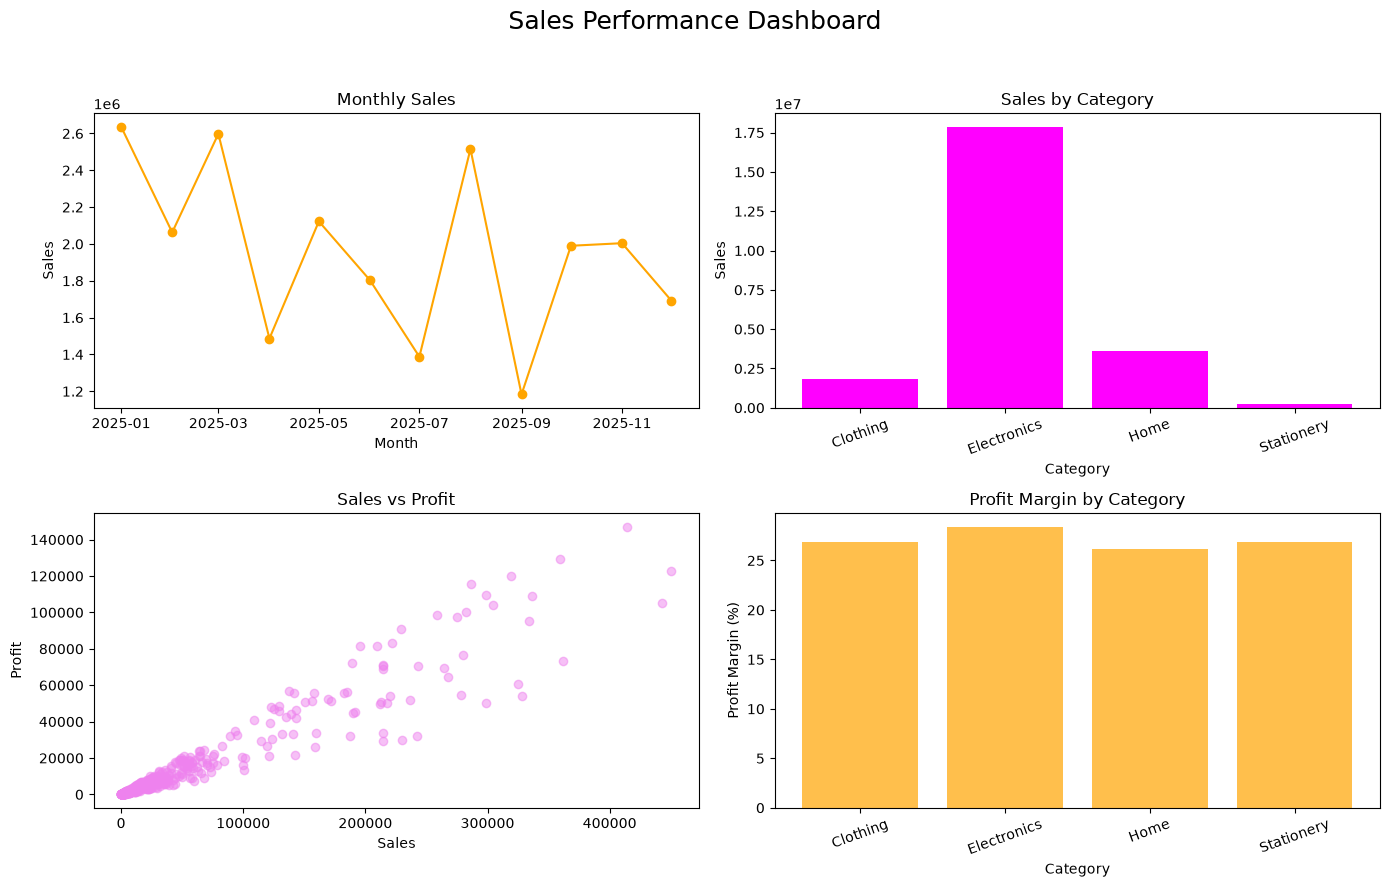

In [36]:
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('mini-project_data1.csv')
data['OrderDate'] = pd.to_datetime(data['OrderDate'])
data = data.sort_values('OrderDate')

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Sales Performance Dashboard', fontsize=18)


# 1. Monthly sales
monthly_sales = data.groupby(
    data['OrderDate'].dt.to_period('M')
)['Sales'].sum()

ax[0, 0].plot(monthly_sales.index.to_timestamp(),monthly_sales.values, marker='o', color='orange')
ax[0, 0].set_title('Monthly Sales')
ax[0, 0].set_xlabel('Month')
ax[0, 0].set_ylabel('Sales')


# 2. Sales by Category
sales_by_category = data.groupby('Category')['Sales'].sum()

ax[0, 1].bar(sales_by_category.index, sales_by_category.values, color='magenta')
ax[0, 1].set_title('Sales by Category')
ax[0, 1].set_xlabel('Category')
ax[0, 1].set_ylabel('Sales')
ax[0, 1].tick_params(axis='x', rotation=20)


# 3. Sales vs Profit
ax[1, 0].scatter(data['Sales'], data['Profit'], alpha=0.5, color='violet')
ax[1, 0].set_title('Sales vs Profit')
ax[1, 0].set_xlabel('Sales')
ax[1, 0].set_ylabel('Profit')


# 4. Profit margin by category
category_performance = data.groupby('Category')[['Sales', 'Profit']].sum()
category_performance['Profit_Margin'] = (
    category_performance['Profit'] /
    category_performance['Sales']
) * 100

ax[1, 1].bar(category_performance.index, category_performance['Profit_Margin'], alpha=0.7, color='orange')
ax[1, 1].set_title('Profit Margin by Category')
ax[1, 1].set_ylabel('Profit Margin (%)')
ax[1, 1].set_xlabel('Category')
ax[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()

# Conclusion: 5 business insights

1. Electronics is the highest-selling category, generating the most total sales revenue.

2. Electronics has the highest profit margin, followed by Clothing and Stationery.

3. Monthly sales fluctuate throughout the year, with January recording the highest sales and September the lowest.

4. There is a positive relationship between sales revenue and profit, meaning higher-revenue orders generally generate higher profits.

5. Sales performance varies across product categories, indicating that different categories contribute differently to overall business revenue.